#Case-study simulation for the adaptive multimodal biometric fusion framework

This notebook separates correctness, coverage, abstention, and accuracy on answered trials. Abstentions contribute zero to the overall correctness metric, so coverage and conditional accuracy are also reported separately.

*Environment and plotting style*

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, beta as beta_dist
from IPython.display import display

%matplotlib inline
plt.rcParams.update({
    "figure.figsize": (10, 5.5), "figure.dpi": 120,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.labelsize": 11,
    "font.size": 10, "legend.frameon": False, "grid.alpha": 0.25
})

### 1. Parameters and scenarios

S4 is the primary scenario. Periocular availability is fixed at 0.90; face availability and quality distribution vary by scenario

In [ ]:
A_F, A_P = 0.90, 0.85
CHANCE = 0.02
BETA_HIGH, BETA_LOW = (5, 1), (1, 2)
Z95 = 1.96

N = 50_000
P_AVAIL_P = 0.90
TAU_DEFAULT, SIGMA_DEFAULT = 0.30, 0.15
CONDS = ("C1", "C2", "C3", "C4", "C5")
SCENARIOS = {
    "S4": dict(p_avail_f=0.60, beta=BETA_LOW,  seed=44),  # primary
    "S1": dict(p_avail_f=0.95, beta=BETA_HIGH, seed=41),
    "S2": dict(p_avail_f=0.95, beta=BETA_LOW,  seed=42),
    "S3": dict(p_avail_f=0.60, beta=BETA_HIGH, seed=43),
}
SCENARIO_ORDER = ["S1", "S2", "S3", "S4"]
print(f"N={N:,} trials/scenario | tau={TAU_DEFAULT} | sigma={SIGMA_DEFAULT}")

N=50,000 trials/scenario | tau=0.3 | sigma=0.15


### 2. Simulation functions

generate_trials creates shared trial draws. A Gaussian copula is used when rho is nonzero, preserving the Beta marginal distributions while inducing quality correlation.

In [ ]:
def pc(a, q):
    return a * q + CHANCE * (1 - q)

In [ ]:
def g(r):
    """Reliability transform; identity in this case study."""
    return r

In [ ]:
def generate_trials(n, p_avail_f, p_avail_p, beta_params, seed, rho=0.0):
    rng = np.random.default_rng(seed)
    avail_f = rng.random(n) < p_avail_f
    avail_p = rng.random(n) < p_avail_p
    a_b, b_b = beta_params
    q_f, q_p = rng.beta(a_b, b_b, n), rng.beta(a_b, b_b, n)
    z_f, z_p = rng.normal(0, 1, n), rng.normal(0, 1, n)

    if rho != 0.0:
        # Separate stream: rho=0 random draws remain unchanged.
        rng2 = np.random.default_rng(seed + 1000)
        u1 = rng2.standard_normal(n)
        u2 = rho * u1 + np.sqrt(1 - rho**2) * rng2.standard_normal(n)
        q_f = beta_dist.ppf(norm.cdf(u1), a_b, b_b)
        q_p = beta_dist.ppf(norm.cdf(u2), a_b, b_b)

    return dict(avail_f=avail_f, avail_p=avail_p,
                q_f=q_f, q_p=q_p, z_f=z_f, z_p=z_p)

In [ ]:
def weighted_result(pcf, pcp, mask_f, mask_p, wf_raw, wp_raw):
    denom = wf_raw + wp_raw
    any_avail = mask_f | mask_p
    degenerate = any_avail & (denom == 0)
    # Zero-sum tie-break: equal weights across available modalities.
    wf = np.where(degenerate, np.where(mask_f, 1.0, 0.0), wf_raw)
    wp = np.where(degenerate, np.where(mask_p, 1.0, 0.0), wp_raw)
    denom2 = wf + wp
    empty = (~any_avail) | (denom2 == 0)

    corr = np.where(
        empty, 0.0,
        (wf * pcf + wp * pcp) / np.where(denom2 == 0, 1e-9, denom2)
    )
    n_trials = len(corr)
    n_answered = max(empty.size - empty.sum(), 1)
    coverage = 1 - empty.mean()

    return dict(
        corr=corr,
        correct=corr.mean(),
        abst=empty.mean(),
        coverage=coverage,
        acc_answered=corr.sum() / n_answered,
        half_ci=Z95 * corr.std(ddof=1) / np.sqrt(n_trials)
    )

In [ ]:
def evaluate(t, tau, sigma):
    af, ap = t["avail_f"], t["avail_p"]
    r_f = np.clip(t["q_f"] + t["z_f"] * sigma, 0, 1)
    r_p = np.clip(t["q_p"] + t["z_p"] * sigma, 0, 1)
    pcf, pcp = pc(A_F, t["q_f"]), pc(A_P, t["q_p"])

    both = af & ap
    sel_f = np.where(af, r_f, -np.inf) > tau
    sel_p = np.where(ap, r_p, -np.inf) > tau
    one, zero = np.ones_like(r_f), np.zeros_like(r_f)

    return {
        "C1": weighted_result(pcf, pcp, both, both,
            np.where(both, one, zero), np.where(both, one, zero)),
        "C2": weighted_result(pcf, pcp, both, both,
            np.where(both, g(r_f), 0.0), np.where(both, g(r_p), 0.0)),
        "C3": weighted_result(pcf, pcp, af, ap,
            np.where(af, one, zero), np.where(ap, one, zero)),
        "C4": weighted_result(pcf, pcp, af, ap,
            np.where(af, g(r_f), 0.0), np.where(ap, g(r_p), 0.0)),
        "C5": weighted_result(pcf, pcp, sel_f, sel_p,
            np.where(sel_f, g(r_f), 0.0), np.where(sel_p, g(r_p), 0.0)),
    }

In [ ]:
def run_experiment(rho=0.0):
    results, cache = {}, {}
    for name, cfg in SCENARIOS.items():
        trials = generate_trials(
            N, cfg["p_avail_f"], P_AVAIL_P, cfg["beta"], cfg["seed"], rho
        )
        cache[name] = trials
        results[name] = evaluate(trials, TAU_DEFAULT, SIGMA_DEFAULT)
    return results, cache

In [ ]:
def metric_table(results, metric):
    rows = []
    for scenario in SCENARIO_ORDER:
        rows.append({
            "Scenario": scenario,
            **{cond: results[scenario][cond][metric] for cond in CONDS}
        })
    return pd.DataFrame(rows).set_index("Scenario")

### 3. Main experiment — independent quality (rho = 0)

The tables below keep the main outcomes separate. The 95% half-width is calculated for mean correctness across all trials, including abstentions scored as zero.

In [ ]:
results_rho0, trial_cache_rho0 = run_experiment(rho=0.0)

print("Experimental configuration")
display(pd.DataFrame([
    ("Trials per scenario", f"{N:,}"),
    ("Face correctness coefficient", A_F),
    ("Periocular correctness coefficient", A_P),
    ("Chance floor", CHANCE),
    ("Face availability", "0.95 for S1/S2; 0.60 for S3/S4"),
    ("Periocular availability", P_AVAIL_P),
    ("Selection threshold tau", TAU_DEFAULT),
    ("Estimator noise sigma", SIGMA_DEFAULT),
], columns=["Parameter", "Value"]).set_index("Parameter"))

Experimental configuration


,Value
Parameter,
Trials per scenario,"50,000"
Face correctness coefficient,0.9
Periocular correctness coefficient,0.85
Chance floor,0.02
Face availability,0.95 for S1/S2; 0.60 for S3/S4
Periocular availability,0.9
Selection threshold tau,0.3
Estimator noise sigma,0.15


In [ ]:
correct_table = metric_table(results_rho0, "correct")
coverage_table = metric_table(results_rho0, "coverage")
abstention_table = metric_table(results_rho0, "abst")
answered_table = metric_table(results_rho0, "acc_answered")
ci_table = metric_table(results_rho0, "half_ci")

In [ ]:
print("A. Correctness (abstention = 0)")
display(correct_table.style.format("{:.3f}").background_gradient(cmap="YlGn", axis=None))

A. Correctness (abstention = 0)


,C1,C2,C3,C4,C5
Scenario,,,,,
S1,0.628,0.638,0.730,0.740,0.740
S2,0.260,0.312,0.303,0.356,0.323
S3,0.395,0.401,0.697,0.703,0.702
S4,0.165,0.198,0.290,0.323,0.277


In [ ]:
print("B. Coverage")
display(coverage_table.style.format("{:.1%}").background_gradient(cmap="Blues", axis=None))

B. Coverage


,C1,C2,C3,C4,C5
Scenario,,,,,
S1,85.8%,85.8%,99.5%,99.5%,99.4%
S2,85.4%,85.4%,99.5%,99.5%,71.8%
S3,54.0%,54.0%,96.2%,96.2%,95.7%
S4,54.0%,54.0%,95.8%,95.8%,62.4%


In [ ]:
print("C. Abstention rate")
display(abstention_table.style.format("{:.1%}").background_gradient(cmap="OrRd", axis=None))

C. Abstention rate


,C1,C2,C3,C4,C5
Scenario,,,,,
S1,14.2%,14.2%,0.5%,0.5%,0.6%
S2,14.6%,14.6%,0.5%,0.5%,28.2%
S3,46.0%,46.0%,3.8%,3.8%,4.3%
S4,46.0%,46.0%,4.2%,4.2%,37.6%


In [ ]:
print("D. Accuracy on answered trials")
display(answered_table.style.format("{:.3f}").background_gradient(cmap="YlGn", axis=None))

D. Accuracy on answered trials


,C1,C2,C3,C4,C5
Scenario,,,,,
S1,0.732,0.743,0.734,0.743,0.745
S2,0.304,0.366,0.305,0.358,0.450
S3,0.731,0.742,0.725,0.731,0.734
S4,0.305,0.367,0.303,0.337,0.445


In [ ]:
print("E. 95% CI half-width for correctness")
display(ci_table.style.format("{:.4f}"))

E. 95% CI half-width for correctness


,C1,C2,C3,C4,C5
Scenario,,,,,
S1,0.0023,0.0024,0.0009,0.0009,0.0009
S2,0.0015,0.0018,0.0013,0.0016,0.0021
S3,0.0032,0.0033,0.0015,0.0015,0.0015
S4,0.0016,0.0020,0.0015,0.0017,0.0022


#### Visual comparison

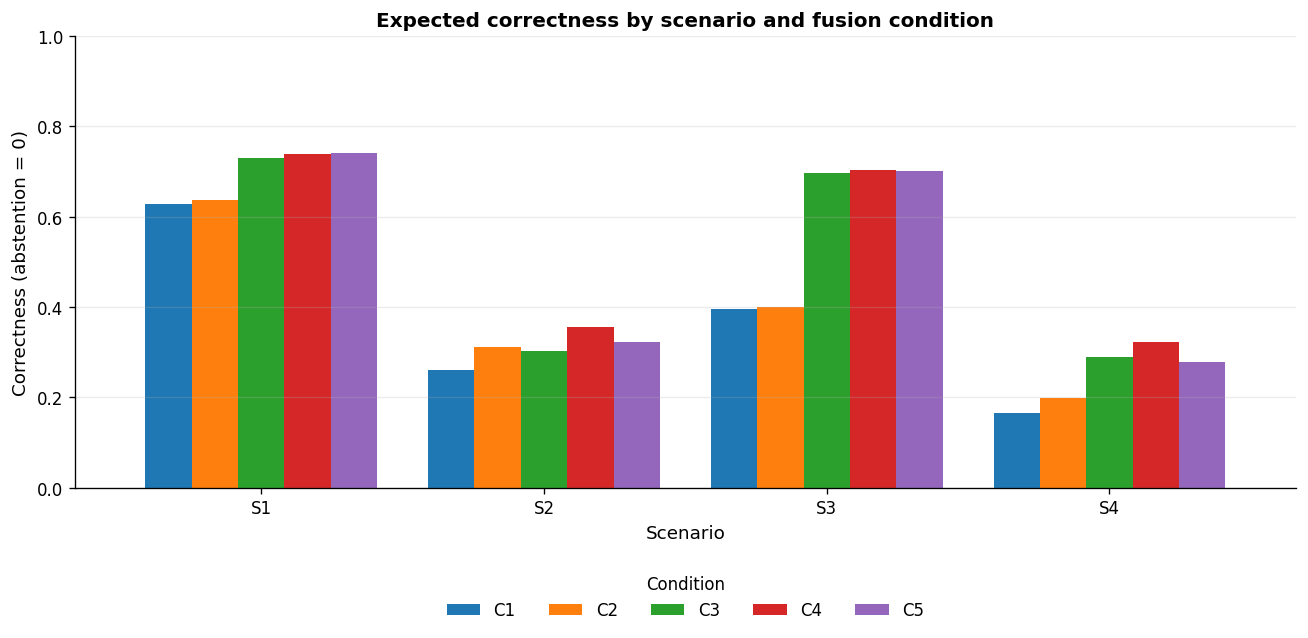

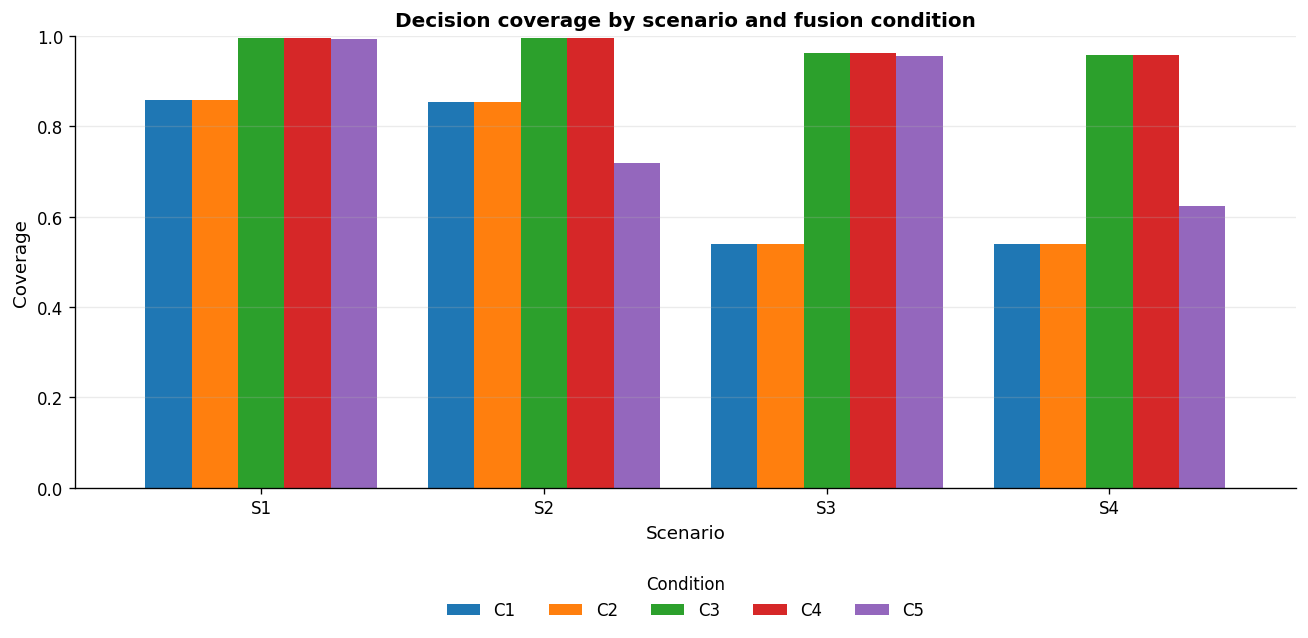

In [ ]:
ax = correct_table.plot(kind="bar", figsize=(11, 5.5), width=0.82)
ax.set_title("Expected correctness by scenario and fusion condition")
ax.set_xlabel("Scenario")
ax.set_ylabel("Correctness (abstention = 0)")
ax.set_ylim(0, 1)
ax.grid(axis="y")
ax.legend(title="Condition", ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.16))
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

ax = coverage_table.plot(kind="bar", figsize=(11, 5.5), width=0.82)
ax.set_title("Decision coverage by scenario and fusion condition")
ax.set_xlabel("Scenario")
ax.set_ylabel("Coverage")
ax.set_ylim(0, 1)
ax.grid(axis="y")
ax.legend(title="Condition", ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.16))
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 4. Primary analysis — S4: C4 versus C5

C4 and C5 are compared on the exact same S4 trials. The paired interval is computed from trial-wise differences, not by combining two independent confidence intervals.

In [ ]:
s4_results = results_rho0["S4"]
diff_c4_c5 = s4_results["C4"]["corr"] - s4_results["C5"]["corr"]
paired_mean = diff_c4_c5.mean()
paired_half_ci = Z95 * diff_c4_c5.std(ddof=1) / np.sqrt(N)

comparison_s4 = pd.DataFrame([
    {
        "Condition": cond,
        "Correctness": s4_results[cond]["correct"],
        "Coverage": s4_results[cond]["coverage"],
        "Abstention": s4_results[cond]["abst"],
        "Accuracy on answered": s4_results[cond]["acc_answered"],
        "95% CI half-width": s4_results[cond]["half_ci"],
    }
    for cond in ["C4", "C5"]
]).set_index("Condition")

display(comparison_s4.style.format({
    "Correctness": "{:.4f}", "Coverage": "{:.1%}",
    "Abstention": "{:.1%}", "Accuracy on answered": "{:.4f}",
    "95% CI half-width": "{:.4f}"
}).background_gradient(cmap="Blues", subset=["Correctness", "Coverage", "Accuracy on answered"]))

print(f"Paired difference C4 − C5 = {paired_mean:.4f} ± {paired_half_ci:.4f} (95% CI half-width)")

,Correctness,Coverage,Abstention,Accuracy on answered,95% CI half-width
Condition,,,,,
C4,0.3232,95.8%,4.2%,0.3373,0.0017
C5,0.2774,62.4%,37.6%,0.4446,0.0022


Paired difference C4 − C5 = 0.0458 ± 0.0009 (95% CI half-width)


### 5. Sensitivity analysis — S4

Each sweep reuses the same S4 random trials. Only the named parameter changes.

*Threshold sweep: vary tau while sigma remains fixed.*

In [ ]:
s4_trials = trial_cache_rho0["S4"]

tau_rows = []
for tau in [0.1, 0.2, 0.3, 0.4, 0.5]:
    e = evaluate(s4_trials, tau, SIGMA_DEFAULT)
    tau_rows.append({
        "tau": tau,
        "C4 correctness": e["C4"]["correct"],
        "C5 correctness": e["C5"]["correct"],
        "C5 coverage": e["C5"]["coverage"],
        "C5 abstention": e["C5"]["abst"],
        "C5 accuracy answered": e["C5"]["acc_answered"],
    })
tau_df = pd.DataFrame(tau_rows).set_index("tau")

print("A. Threshold sweep (sigma = 0.15)")
display(tau_df.style.format({
    "C4 correctness": "{:.4f}", "C5 correctness": "{:.4f}",
    "C5 coverage": "{:.1%}", "C5 abstention": "{:.1%}",
    "C5 accuracy answered": "{:.4f}"
}).background_gradient(cmap="YlGn", subset=["C5 correctness", "C5 coverage"]))


A. Threshold sweep (sigma = 0.15)


,C4 correctness,C5 correctness,C5 coverage,C5 abstention,C5 accuracy answered
tau,,,,,
0.100000,0.3232,0.3119,84.2%,15.8%,0.3706
0.200000,0.3232,0.2999,74.5%,25.5%,0.4024
0.300000,0.3232,0.2774,62.4%,37.6%,0.4446
0.400000,0.3232,0.2425,49.3%,50.7%,0.4918
0.500000,0.3232,0.1979,36.6%,63.4%,0.5406


*Noise sweep: vary sigma while tau remains fixed.*

In [ ]:
sigma_rows = []
for sigma in [0.05, 0.15, 0.30, 0.50]:
    e = evaluate(s4_trials, TAU_DEFAULT, sigma)
    sigma_rows.append({
        "sigma": sigma,
        "C4 correctness": e["C4"]["correct"],
        "C5 correctness": e["C5"]["correct"],
        "C5 coverage": e["C5"]["coverage"],
        "C5 abstention": e["C5"]["abst"],
        "C5 accuracy answered": e["C5"]["acc_answered"],
    })
sigma_df = pd.DataFrame(sigma_rows).set_index("sigma")

print("B. Estimator-noise sweep (tau = 0.30)")
display(sigma_df.style.format({
    "C4 correctness": "{:.4f}", "C5 correctness": "{:.4f}",
    "C5 coverage": "{:.1%}", "C5 abstention": "{:.1%}",
    "C5 accuracy answered": "{:.4f}"
}).background_gradient(cmap="YlGn", subset=["C5 correctness", "C5 coverage"]))

B. Estimator-noise sweep (tau = 0.30)


,C4 correctness,C5 correctness,C5 coverage,C5 abstention,C5 accuracy answered
sigma,,,,,
0.050000,0.3256,0.2871,60.8%,39.2%,0.4725
0.150000,0.3232,0.2774,62.4%,37.6%,0.4446
0.300000,0.3173,0.2561,63.7%,36.3%,0.4023
0.500000,0.3101,0.2358,63.5%,36.5%,0.3713


#### Sensitivity plots

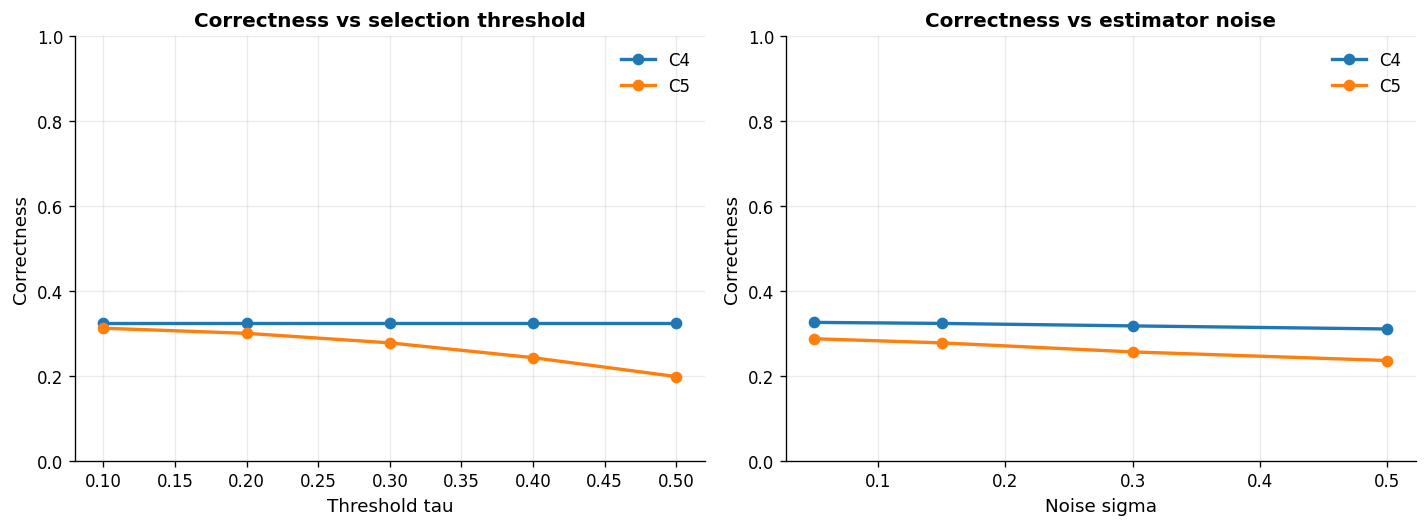

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(tau_df.index, tau_df["C4 correctness"], marker="o", linewidth=2, label="C4")
axes[0].plot(tau_df.index, tau_df["C5 correctness"], marker="o", linewidth=2, label="C5")
axes[0].set(title="Correctness vs selection threshold", xlabel="Threshold tau", ylabel="Correctness", ylim=(0, 1))
axes[0].grid(True); axes[0].legend()

axes[1].plot(sigma_df.index, sigma_df["C4 correctness"], marker="o", linewidth=2, label="C4")
axes[1].plot(sigma_df.index, sigma_df["C5 correctness"], marker="o", linewidth=2, label="C5")
axes[1].set(title="Correctness vs estimator noise", xlabel="Noise sigma", ylabel="Correctness", ylim=(0, 1))
axes[1].grid(True); axes[1].legend()
plt.tight_layout()
plt.show()

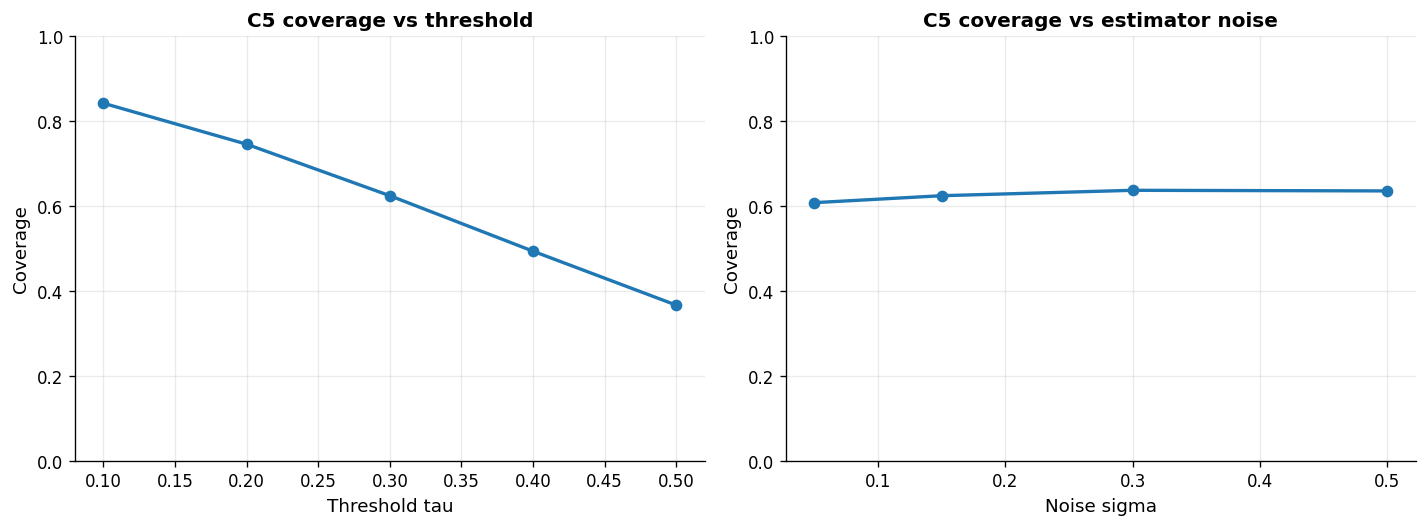

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(tau_df.index, tau_df["C5 coverage"], marker="o", linewidth=2)
axes[0].set(title="C5 coverage vs threshold", xlabel="Threshold tau", ylabel="Coverage", ylim=(0, 1))
axes[0].grid(True)
axes[1].plot(sigma_df.index, sigma_df["C5 coverage"], marker="o", linewidth=2)
axes[1].set(title="C5 coverage vs estimator noise", xlabel="Noise sigma", ylabel="Coverage", ylim=(0, 1))
axes[1].grid(True)
plt.tight_layout()
plt.show()

### 6. Optional robustness check — correlated quality (rho = 0.6)

This repeats the experiment with correlated face/periocular quality while preserving the Beta marginals.

In [ ]:
results_rho06, trial_cache_rho06 = run_experiment(rho=0.6)

print("A. Correctness (rho = 0.6)")
display(metric_table(results_rho06, "correct").style.format("{:.3f}").background_gradient(cmap="YlGn", axis=None))

A. Correctness (rho = 0.6)


,C1,C2,C3,C4,C5
Scenario,,,,,
S1,0.628,0.632,0.730,0.734,0.734
S2,0.260,0.283,0.304,0.327,0.284
S3,0.396,0.398,0.698,0.700,0.699
S4,0.165,0.180,0.291,0.305,0.253


In [ ]:
print("B. Coverage (rho = 0.6)")
display(metric_table(results_rho06, "coverage").style.format("{:.1%}").background_gradient(cmap="Blues", axis=None))

B. Coverage (rho = 0.6)


,C1,C2,C3,C4,C5
Scenario,,,,,
S1,85.8%,85.8%,99.5%,99.5%,99.3%
S2,85.4%,85.4%,99.5%,99.5%,65.6%
S3,54.0%,54.0%,96.2%,96.2%,95.7%
S4,54.0%,54.0%,95.8%,95.8%,58.4%


In [ ]:
print("C. Accuracy on answered trials (rho = 0.6)")
display(metric_table(results_rho06, "acc_answered").style.format("{:.3f}").background_gradient(cmap="YlGn", axis=None))

C. Accuracy on answered trials (rho = 0.6)


,C1,C2,C3,C4,C5
Scenario,,,,,
S1,0.732,0.737,0.733,0.738,0.739
S2,0.304,0.331,0.305,0.329,0.432
S3,0.733,0.737,0.726,0.728,0.731
S4,0.306,0.333,0.303,0.319,0.433
